# HetMap results analysis (unified supervised-200 run)

One notebook for **RQ1, RQ2 and RQ3**. It reads the supervisor's package `hetmap-supervised200-results-20261015`
(ZIP or extracted folder), recomputes the statistics, checks them against the package, and writes **only what the paper uses**:

| Paper item | File written |
|---|---|
| RQ1 table: medians | `generated/rq1_mlp_features.tex` |
| RQ1 table: pairwise summary | `generated/rq1_stats.tex` |
| RQ2 table: graph steps | `generated/rq2_stats.tex` |
| RQ2 figure (macro, micro) | `Images/RQ2_lineplot_f1_macro.pdf`, `Images/RQ2_lineplot_f1_micro.pdf` |
| RQ2 directory baseline table | `generated/directory_baseline.tex` |
| RQ3 table: neighbor effect by vector | `generated/rq3_systems_body.tex` |
| RQ3 table: per-system N2V | `generated/rq3_n2v.tex` |
| RQ3 table: predictor comparison | `generated/rq3_encoders.tex` |
| RQ3 figure | `Images/rq3_n2v.pdf` |
| Statistics for citing / checking | `results/unified200/stats/*.csv` |

**Design:** ten systems, 100 saved splits, 200 supervised epochs, no self-training, merged dependency relation, one frozen embedding per system, 45,000 fits.
RQ exports overlap on purpose (RQ1 = neighbor-MLP *off*, RQ2 *F* = directed HGT).
**Statistics:** paired two-sided Wilcoxon on the 100 split-level differences, Holm within each comparison family and metric, Cliff's delta (N/S/M/L).
Table cells for RQ2 use the median over systems of the difference of configuration medians; RQ3 uses the median over systems of the paired within-split change.

**Where to put it:** anywhere inside the paper folder (it walks up until it finds `3a_results.tex`). The package ZIP can sit in the paper folder, in `results/`, or next to it;
otherwise set `PACKAGE_PATH` below. If no paper folder is found, outputs go to `results/unified200/preview/`.

## 1. Setup

In [1]:
import json, warnings
from itertools import combinations
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")
plt.rcParams["text.usetex"] = True
try:  # fall back to mathtext if no LaTeX installation is available
    _f = plt.figure(); _f.text(0.5, 0.5, r"$\langle k \rangle$"); _f.canvas.draw(); plt.close(_f)
except Exception as _e:
    print("LaTeX unavailable, using mathtext:", type(_e).__name__)
    plt.rcParams["text.usetex"] = False
sns.set_theme(
    style="ticks",
    rc={
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.spines.left": True, "axes.spines.bottom": True,
        "axes.edgecolor": "black", "axes.linewidth": 1,
        "xtick.bottom": True, "ytick.left": True,
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 1, "ytick.major.width": 1,
        "axes.grid": True, "axes.grid.axis": "x",
        "grid.alpha": 0.7, "grid.linestyle": "-", "grid.linewidth": 0.7,
    },
)
plt.rcParams.update({
    "font.size": 11, "axes.axisbelow": True,
    "grid.alpha": 0.4, "grid.linestyle": "-", "grid.linewidth": 0.5,
})
ALPHA = 0.05

LaTeX unavailable, using mathtext: RuntimeError


<Figure size 640x480 with 0 Axes>

In [2]:
# ── Paths ───────────────────────────────────────────────────────────────────────
# The notebook finds the paper folder (the one holding 3a_results.tex) and reads the supervisor's
# package either from an extracted folder or straight from the ZIP in the repo root.
def _find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "3a_results.tex").exists():
            return q
    raise FileNotFoundError("Run this notebook from inside the HetMap paper folder (the one with 3a_results.tex).")

# Optional overrides: set these if the notebook is not inside the paper folder or the package lives elsewhere.
PAPER_DIR = None          # e.g. Path(r"C:\path\to\paper")
PACKAGE_PATH = None       # e.g. Path(r"C:\path\to\hetmap-supervised200-results-20261015.zip") or the extracted folder

try:
    ROOT = Path(PAPER_DIR).resolve() if PAPER_DIR else _find_root()
    PAPER_FOUND = True
except FileNotFoundError:
    ROOT = Path.cwd().resolve()
    PAPER_FOUND = False
    print("Paper folder (3a_results.tex) not found: writing to results/unified200/preview/ instead.")
PKG_NAME = "hetmap-supervised200-results-20261015"
RUN_DIR = "scenario1-run/unified-supervised200-20261015/outputs/analysis"   # long-format.csv, rq*-per-run.csv, ...
AUDIT_DIR = "repro-audit/unified200-20261015"                              # supervisor's statistics / directory audit


class Package:
    """Read-only access to the supervisor's results package (extracted folder or .zip)."""
    def __init__(self, root):
        bases = [root, root / "results", root.parent]
        self.folder = next((b / PKG_NAME for b in bases if (b / PKG_NAME).is_dir()), None)
        self.zip = None
        if self.folder is None:
            z = next((b / f"{PKG_NAME}.zip" for b in bases if (b / f"{PKG_NAME}.zip").exists()), None)
            if z is None:
                raise FileNotFoundError(f"Put {PKG_NAME}.zip (or the extracted folder) next to this notebook.")
            self.zip = zipfile.ZipFile(z)
        self.source = self.folder or Path(self.zip.filename)

    def open(self, rel):
        return (self.folder / rel).open("rb") if self.folder else self.zip.open(f"{PKG_NAME}/{rel}")

    def csv(self, rel, **kw):
        with self.open(rel) as fh:
            return pd.read_csv(fh, **kw)

    def json(self, rel):
        with self.open(rel) as fh:
            return json.load(fh)


if PACKAGE_PATH:
    _p = Path(PACKAGE_PATH)
    _bases = [_p.parent] if _p.suffix == ".zip" else [_p.parent]
    ROOT_FOR_PKG = _p.parent
    PKG_NAME = _p.stem if _p.suffix == ".zip" else _p.name
    PKG = Package(ROOT_FOR_PKG)
else:
    PKG = Package(ROOT)

# Where outputs go. WRITE_TO_PAPER=True overwrites generated/*.tex and Images/*.pdf (git keeps the old versions);
# False writes everything under results/unified200/preview/ so the paper folder is untouched.
WRITE_TO_PAPER = PAPER_FOUND   # True: overwrite generated/*.tex and Images/*.pdf in the paper folder
OUT = ROOT / "results" / "unified200"
STATS_DIR = OUT / "stats"
TEX_DIR = ROOT / "generated" if WRITE_TO_PAPER else OUT / "preview" / "generated"
FIG_DIR = ROOT / "Images" if WRITE_TO_PAPER else OUT / "preview" / "Images"
for _d in (STATS_DIR, TEX_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_stats(df, name):
    p = STATS_DIR / name
    df.to_csv(p, index=False)
    print(f"saved {p.relative_to(ROOT)}  ({len(df)} rows)")


def save_tex(text, name):
    p = TEX_DIR / name
    p.write_text(text)
    print(f"wrote {p.relative_to(ROOT)}")


def fig_path(name):
    return FIG_DIR / name


print("ROOT    :", ROOT)
print("PACKAGE :", PKG.source)
print("TEX     :", TEX_DIR.relative_to(ROOT))
print("FIGURES :", FIG_DIR.relative_to(ROOT))

SYSTEMS_RAW = ["A.UML", "C.Img", "Jabref", "Lucene", "SH-3D", "TeamMates", "Bash", "HDF", "Chrome", "HDC"]
SYS_RENAME = {"Jabref": "JabRef", "TeamMates": "T.Mates"}
DATASET_ORDER = [SYS_RENAME.get(s, s) for s in SYSTEMS_RAW]
METRICS = ["f1_macro", "f1_micro"]
METRIC_NAME = {"f1_macro": "Macro-F1", "f1_micro": "Micro-F1"}
REP_LABEL = {"W2V": "W2V", "N2V": "N2V", "UXC_ZS": r"\zs{}", "UXC_FT": r"\ft{}"}        # LaTeX macros of the paper
REP_PLOT = {"W2V": "W2V", "N2V": "N2V", "UXC_ZS": r"UXC$_{ZS}$", "UXC_FT": r"UXC$_{FT}$"}   # matplotlib labels
REP_COLOR = {"W2V": "#A6CEE3", "N2V": "#B2DF8A", "UXC_ZS": "#FB9A99", "UXC_FT": "#CAB2D6"}

ROOT    : /home/user/HetMap
PACKAGE : /home/user/HetMap/hetmap-supervised200-results-20261015.zip
TEX     : generated
FIGURES : Images


## 2. Load and validate the data

In [3]:
long = PKG.csv(f"{RUN_DIR}/long-format.csv")
assert len(long) == 45000 and PKG.json(f"{RUN_DIR}/validation.json")["complete"] is True
print("fits:", len(long), "| systems:", long.system.nunique(), "| splits per cell:", long.run_id.nunique(),
      "| schedule:", list(long.schedule.unique()), "| epochs:", list(long.epochs.unique()))

REPS = ["N2V", "W2V", "UXC_ZS", "UXC_FT"]                    # RQ1 / RQ3 column order of the paper tables
RQ1_REPS = ["W2V", "N2V", "UXC_ZS", "UXC_FT"]
RQ2_REPS = ["W2V", "N2V", "UXC_FT"]
RQ2_CONFIGS = ["MLP", "F", "FM", "FF", "FFM"]
MODELS = ["HGT", "GAT", "NeighborMLP"]

def check_cells(df, n_cells):
    n = df.groupby(["system", "representation", "config", "model", "condition"]).size()
    assert len(n) == n_cells and (n == 100).all(), (len(n), n.describe())

# RQ1: feature-only classifier = neighbor-MLP with neighbors off
rq1 = long[(long.model == "NeighborMLP") & (long.condition == "off")].copy(); check_cells(rq1, 40)
# RQ2: HGT on the directed merged graph with F / FM / FF / FFM (zero-shot UniXcoder is not part of RQ2)
rq2 = long[(long.model == "HGT") & (long.condition == "directed") & long.config.isin(["F", "FM", "FF", "FFM"])
           & long.representation.isin(RQ2_REPS)].copy(); check_cells(rq2, 120)
# RQ3: every F-configuration fit: 4 vectors x 3 models x {off, directed, undirected}
rq3 = long[long.config == "F"].copy(); check_cells(rq3, 360)

for name, df in [("rq1-per-run.csv", rq1), ("rq2-per-run.csv", rq2), ("rq3-per-run.csv", rq3)]:
    ref = PKG.csv(f"{RUN_DIR}/{name}")
    k = ["system", "representation", "config", "model", "condition", "run_id"]
    m = ref.merge(df, on=k, suffixes=("_ref", ""), validate="one_to_one")
    assert len(m) == len(ref) == len(df) and np.allclose(m.f1_macro, m.f1_macro_ref) and np.allclose(m.f1_micro, m.f1_micro_ref)
print("OK: RQ1 (4,000), RQ2 (12,000) and RQ3 (36,000) rows match the package exports")

fits: 45000 | systems: 10 | splits per cell: 100 | schedule: ['supervised200'] | epochs: [np.int64(200)]


OK: RQ1 (4,000), RQ2 (12,000) and RQ3 (36,000) rows match the package exports


## 3. Statistical helpers

In [4]:
# ── Statistical helpers (same procedure as the supervisor's analyze_results.py) ─────────────────
# Paired two-sided Wilcoxon signed-rank on the 100 split-level differences (normal approximation, differences
# rounded to 12 decimals), Cliff's delta, Holm correction within each comparison family and metric.
def cliff_band(d):
    a = abs(d)
    return "N" if a < 0.147 else "S" if a < 0.33 else "M" if a < 0.474 else "L"


def holm(p):
    """Holm-adjusted p-values in the original order."""
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    prev = 0.0
    for rank, idx in enumerate(order):
        prev = min(max((len(p) - rank) * p[idx], prev), 1.0)
        adj[idx] = prev
    return adj


def _cell(df, system):
    g = df[df["system"] == system].set_index("run_id").sort_index()
    assert list(g.index) == list(range(100)), f"{system}: expected run_id 0..99"
    return g


def paired_compare(a, b, scope, family, **labels):
    """Compare two long-format slices (a minus b), per system and metric. Rows are paired by run_id and
    must share the same initial labeled set (labeled_ids_sha256)."""
    rows = []
    for system in SYSTEMS_RAW:
        ga, gb = _cell(a, system), _cell(b, system)
        assert (ga.labeled_ids_sha256 == gb.labeled_ids_sha256).all(), f"{system}: unpaired splits in {family}"
        for metric in METRICS:
            x, y = ga[metric].to_numpy(), gb[metric].to_numpy()
            diff = np.round(x - y, 12)
            p = wilcoxon(diff, alternative="two-sided", method="approx").pvalue if np.any(diff) else 1.0
            delta = float(np.sign(x[:, None] - y[None, :]).mean())
            rows.append(dict(
                scope=scope, family=family, system=system, metric=metric,
                median_a=np.median(x), median_b=np.median(y), difference_of_medians=np.median(x) - np.median(y),
                median_paired_delta=np.median(diff), mean_paired_delta=diff.mean(),
                q25_paired_delta=np.percentile(diff, 25), q75_paired_delta=np.percentile(diff, 75),
                positive_splits=int((diff > 0).sum()), negative_splits=int((diff < 0).sum()), p=p,
                cliffs_delta=delta, cliffs_band=cliff_band(delta), **labels))
    return rows


def finish_stats(rows):
    """Holm within (scope, family, metric); a family is whatever the caller put in `family`."""
    S = pd.DataFrame(rows)
    S["p_holm"] = np.nan
    for _, g in S.groupby(["scope", "family", "metric"]):
        S.loc[g.index, "p_holm"] = holm(g["p"].to_numpy())
    S["significant"] = S["p_holm"] < ALPHA
    S["system"] = S["system"].replace(SYS_RENAME)
    return S


def summarize(S, keys):
    """One row per comparison: median over systems, number of positive systems, significant up / down."""
    out = []
    for key, g in S.groupby(keys, dropna=False):
        out.append(dict(zip(keys, key), **{
            "median_system_difference": g.difference_of_medians.median(),
            "median_system_paired_delta": g.median_paired_delta.median(),
            "positive_systems": int((g.difference_of_medians > 1e-10).sum()),
            "paired_positive_systems": int((g.median_paired_delta > 1e-10).sum()),
            "significant_positive": int((g.significant & (g.median_paired_delta > 0)).sum()),
            "significant_negative": int((g.significant & (g.median_paired_delta < 0)).sum()),
            "large_positive": int((g.significant & (g.cliffs_delta >= .474)).sum()),
            "min_positive_splits": int(g.positive_splits.min()),
        }))
    return pd.DataFrame(out)


def check_against_package(S, scope, extra=()):
    """Recomputed statistics must equal the supervisor's paired_statistics.csv (p, Holm-p, medians, Cliff's delta)."""
    ref = PKG.csv(f"{AUDIT_DIR}/paired_statistics.csv")
    ref = ref[ref.scope == scope].copy()
    ref["system"] = ref["system"].replace(SYS_RENAME)
    key = ["family", "system", "metric", *extra]
    m = S[S.scope == scope].merge(ref, on=key, suffixes=("", "_ref"), validate="one_to_one")
    assert len(m) == len(ref) == (S.scope == scope).sum(), f"{scope}: row mismatch"
    for c in ["median_a", "median_b", "median_paired_delta", "p", "p_holm", "cliffs_delta"]:
        assert np.allclose(m[c], m[c + "_ref"], rtol=1e-9, atol=1e-12), f"{scope}: {c} differs from the package"
    assert (m.significant == m.significant_ref).all()
    print(f"OK: {scope} statistics ({len(m)} tests) reproduce paired_statistics.csv")


# ── LaTeX helpers (shading rules inferred from the existing tables: <1: 25, 1-3: 45, 3-6: 70, >=6: 100) ─
def shade(x):
    a = abs(x)
    return 25 if a < 1 else 45 if a < 3 else 70 if a < 6 else 100


def tex_signed(x, nd=1):
    r = round(float(x), nd)
    if r == 0:
        return f"{0:.{nd}f}"
    return f"+{r:.{nd}f}" if r > 0 else f"$-${abs(r):.{nd}f}"


def shaded(x, text):
    return f"\\{'g' if x >= 0 else 'r'}c{{{shade(x)}}}{text}"

In [5]:
def write_table(text, name):
    """Write a paper table. If the file already exists, only its first (active) table environment is replaced, so commented-out
    old tables and anything else in the file are kept."""
    p = TEX_DIR / name
    if p.exists():
        old = p.read_text()
        i = old.find("\\begin{table")
        if i >= 0:
            j = old.index("\n", old.index("\\end{table", i)) + 1
            p.write_text(old[:i] + text.rstrip("\n") + "\n" + old[j:])
            print(f"updated first table of {p.relative_to(ROOT)}")
            return
    save_tex(text, name)

---
## 4. RQ1: file representations with the feature-only classifier
Planned contrasts: FT-ZS, FT-W2V, FT-N2V, N2V-W2V, plus ZS-W2V (checks the claim that the two dependency-free vectors do not separate). One Holm family per contrast and metric (ten systems).

In [6]:
RQ1_CONTRASTS = [("UXC_ZS", "W2V"), ("UXC_FT", "UXC_ZS"), ("UXC_FT", "W2V"), ("UXC_FT", "N2V"), ("N2V", "W2V")]
rows = []
for a, b in RQ1_CONTRASTS:
    rows += paired_compare(rq1[rq1.representation == a], rq1[rq1.representation == b], "RQ1", f"{a}-{b}", contrast=f"{a}-{b}")
rq1_stats = finish_stats(rows)
check_against_package(rq1_stats, "RQ1")
save_stats(rq1_stats, "rq1_paired_statistics.csv")
rq1_summary = summarize(rq1_stats, ["scope", "contrast", "metric"])

rq1_med = {m: rq1.groupby(["system", "representation"])[m].median().unstack()[RQ1_REPS].reindex(SYSTEMS_RAW).rename(index=SYS_RENAME)
           for m in METRICS}
for m in METRICS:
    t = rq1_med[m].copy(); t["winner"] = t.idxmax(axis=1)
    print(f"=== RQ1 median {METRIC_NAME[m]} (winner counts: {t.winner.value_counts().to_dict()}) ===")
    display(t.round(1))

OK: RQ1 statistics (100 tests) reproduce paired_statistics.csv
saved results/unified200/stats/rq1_paired_statistics.csv  (100 rows)
=== RQ1 median Macro-F1 (winner counts: {'N2V': 6, 'UXC_FT': 2, 'W2V': 1, 'UXC_ZS': 1}) ===


representation,W2V,N2V,UXC_ZS,UXC_FT,winner
system,,,,,
A.UML,33.5,54.5,35.9,46.2,N2V
C.Img,23.2,70.8,32.6,42.3,N2V
JabRef,43.7,40.1,39.4,43.0,W2V
Lucene,57.0,66.3,54.0,62.5,N2V
SH-3D,22.0,42.5,47.8,46.6,UXC_ZS
T.Mates,30.1,41.1,37.3,51.0,UXC_FT
Bash,6.6,42.5,22.8,27.0,N2V
HDF,8.4,52.8,41.6,46.1,N2V
Chrome,14.4,41.1,13.6,31.3,N2V


=== RQ1 median Micro-F1 (winner counts: {'N2V': 6, 'UXC_FT': 4}) ===


representation,W2V,N2V,UXC_ZS,UXC_FT,winner
system,,,,,
A.UML,56.8,71.7,60.5,69.5,N2V
C.Img,39.0,80.2,51.8,62.1,N2V
JabRef,78.0,74.3,75.7,78.7,UXC_FT
Lucene,71.1,79.2,65.6,75.6,N2V
SH-3D,41.1,57.8,64.3,66.9,UXC_FT
T.Mates,55.2,68.3,67.6,78.6,UXC_FT
Bash,28.6,61.5,41.6,49.0,N2V
HDF,22.2,57.2,44.3,48.0,N2V
Chrome,48.4,70.5,48.4,66.2,N2V


In [7]:
# Tables rq1_mlp_features.tex and rq1_stats.tex (existing layout)
NAME = {"UXC_ZS": r"\zs{}", "UXC_FT": r"\ft{}", "W2V": "W2V", "N2V": "N2V"}

def tex_rq1_medians():
    L = [r"\begin{table}[ht]", r"\centering", r"\small", r"\renewcommand{\arraystretch}{1.05}",
         r"\caption{Median macro-F1/micro-F1 scores (\%) across 100 runs for the feature-only MLP using W2V, N2V, and contextual representation variants:\zs{} and \ft{}. "
         r"Highlighted values indicate the highest score for each system and metric.\label{tab:rq1_mlp_features}}",
         r"\begin{adjustbox}{width=\columnwidth}", r"\setlength{\tabcolsep}{11pt}", r"\begin{tabular}{lcccc}", r"\toprule",
         r"System & W2V & N2V & \zs{} & \ft{} \\", r"\midrule"]
    for s in DATASET_ORDER:
        macro = rq1_med["f1_macro"].loc[s].round(0).astype(int); micro = rq1_med["f1_micro"].loc[s].round(0).astype(int)
        c = []
        for r in RQ1_REPS:
            a = rf"\best{{{macro[r]}}}" if macro[r] == macro.max() else str(macro[r])
            b = rf"\best{{{micro[r]}}}" if micro[r] == micro.max() else str(micro[r])
            c.append(rf"{a}\,/\,{b}")
        L += [s] + [f"& {x}" for x in c[:-1]] + [f"& {c[-1]} \\\\", ""]
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table}", ""])

def tex_rq1_stats():
    L = [r"\begin{table}[t]", r"\centering", r"\small",
         r"\caption{Summary of pairwise differences in F1 points across ten systems. $\Delta$ is the median difference (first method minus second); $+$ve counts systems favoring the first method; "
         r"$\uparrow/\downarrow$ gives the number of significant positive/negative differences.\label{tab:rq1_stats}}",
         r"\begin{adjustbox}{max width=\linewidth}", r"\begin{tabular}{lrrrrrr}", r"\toprule",
         r"& \multicolumn{3}{c}{Macro F1} & \multicolumn{3}{c}{Micro F1} \\", r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}",
         r"Comparison & $\Delta$ & $+$ve & $\uparrow/\downarrow$ & $\Delta$ & $+$ve & $\uparrow/\downarrow$ \\", r"\midrule"]
    for a, b in RQ1_CONTRASTS:
        c = []
        for m in METRICS:
            r = rq1_summary[(rq1_summary.contrast == f"{a}-{b}") & (rq1_summary.metric == m)].iloc[0]
            d = tex_signed(r.median_system_difference).replace("+", "$+$")
            d = rf"\best{{{d}}}" if r.median_system_difference < 0 else d
            c += [d, str(r.positive_systems), f"{r.significant_positive}/{r.significant_negative}"]
        L.append(f"{NAME[a]}$-${NAME[b]} & " + " & ".join(c) + r" \\")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table}", ""])

write_table(tex_rq1_medians(), "rq1_mlp_features.tex")
write_table(tex_rq1_stats(), "rq1_stats.tex")
display(rq1_summary.round(2))

updated first table of generated/rq1_mlp_features.tex
updated first table of generated/rq1_stats.tex


,scope,contrast,metric,median_system_difference,median_system_paired_delta,positive_systems,paired_positive_systems,significant_positive,significant_negative,large_positive,min_positive_splits
0,RQ1,N2V-W2V,f1_macro,20.74,20.35,9,9,9,1,9,23
1,RQ1,N2V-W2V,f1_micro,16.09,16.19,9,9,9,1,9,9
2,RQ1,UXC_FT-N2V,f1_macro,-5.25,-4.94,4,4,4,6,1,0
3,RQ1,UXC_FT-N2V,f1_micro,-2.92,-3.26,4,3,3,6,3,0
4,RQ1,UXC_FT-UXC_ZS,f1_macro,9.10,9.10,9,9,9,0,8,47
5,RQ1,UXC_FT-UXC_ZS,f1_micro,9.46,9.15,10,10,10,0,8,76
6,RQ1,UXC_FT-W2V,f1_macro,18.02,17.48,9,9,9,0,9,48
7,RQ1,UXC_FT-W2V,f1_micro,19.11,19.17,10,10,9,0,9,54
8,RQ1,UXC_ZS-W2V,f1_macro,4.78,5.21,6,6,6,4,5,17
9,RQ1,UXC_ZS-W2V,f1_micro,8.05,7.47,7,6,6,3,5,5


In [8]:
# Per-system detail for writing the RQ1 sentences (display only): difference of medians (Cliff band), * = Holm-significant
def _detail(g):
    return " / ".join(f"{g[g.metric == m].iloc[0].difference_of_medians:+.1f} ({g[g.metric == m].iloc[0].cliffs_band})"
                      f"{'*' if g[g.metric == m].iloc[0].significant else ''}" for m in METRICS)
display(rq1_stats.groupby(["system", "contrast"]).apply(_detail).unstack()[[f"{a}-{b}" for a, b in RQ1_CONTRASTS]].reindex(DATASET_ORDER))

contrast,UXC_ZS-W2V,UXC_FT-UXC_ZS,UXC_FT-W2V,UXC_FT-N2V,N2V-W2V
system,,,,,
A.UML,+2.4 (M)* / +3.7 (M)*,+10.2 (L)* / +9.0 (L)*,+12.6 (L)* / +12.7 (L)*,-8.3 (L)* / -2.2 (M)*,+21.0 (L)* / +14.9 (L)*
C.Img,+9.5 (L)* / +12.9 (L)*,+9.7 (L)* / +10.3 (L)*,+19.2 (L)* / +23.1 (L)*,-28.5 (L)* / -18.1 (L)*,+47.6 (L)* / +41.2 (L)*
JabRef,-4.3 (L)* / -2.3 (L)*,+3.6 (L)* / +3.0 (L)*,-0.7 (N) / +0.7 (N),+2.9 (M)* / +4.4 (L)*,-3.6 (M)* / -3.7 (L)*
Lucene,-3.0 (M)* / -5.4 (L)*,+8.5 (L)* / +9.9 (L)*,+5.5 (L)* / +4.5 (L)*,-3.8 (M)* / -3.6 (L)*,+9.3 (L)* / +8.1 (L)*
SH-3D,+25.9 (L)* / +23.2 (L)*,-1.3 (N) / +2.6 (M)*,+24.6 (L)* / +25.8 (L)*,+4.0 (M)* / +9.1 (L)*,+20.5 (L)* / +16.7 (L)*
T.Mates,+7.1 (L)* / +12.4 (L)*,+13.8 (L)* / +11.0 (L)*,+20.9 (L)* / +23.4 (L)*,+9.9 (L)* / +10.2 (L)*,+11.0 (L)* / +13.2 (L)*
Bash,+16.2 (L)* / +13.0 (L)*,+4.2 (L)* / +7.5 (L)*,+20.4 (L)* / +20.5 (L)*,-15.4 (L)* / -12.5 (L)*,+35.8 (L)* / +32.9 (L)*
HDF,+33.2 (L)* / +22.0 (L)*,+4.5 (M)* / +3.7 (M)*,+37.7 (L)* / +25.7 (L)*,-6.7 (L)* / -9.2 (L)*,+44.4 (L)* / +35.0 (L)*
Chrome,-0.8 (M)* / +0.0 (N),+17.7 (L)* / +17.8 (L)*,+16.9 (L)* / +17.8 (L)*,-9.9 (L)* / -4.3 (L)*,+26.8 (L)* / +22.1 (L)*


---
## 5. RQ2: file, member and folder configurations
MLP = RQ1 neighbor-MLP off; F / FM / FF / FFM = HGT on the merged, directed graph; UniXcoder = fine-tuned. One Holm family per graph step and metric (30 tests = 10 systems x 3 vectors).
Treat these as configuration comparisons: FM is not a strict addition of usable context to F (one message-passing layer; W2V also changes how member text enters the model).

In [9]:
RQ2_STEPS = [("F", "MLP"), ("FM", "F"), ("FFM", "FF"), ("FF", "F"), ("FFM", "FM")]   # row order of the paper table

def rq2_slice(rep, cfg):
    return rq1[rq1.representation == rep] if cfg == "MLP" else rq2[(rq2.representation == rep) & (rq2.config == cfg)]

rows = []
for a, b in RQ2_STEPS:
    for rep in RQ2_REPS:
        rows += paired_compare(rq2_slice(rep, a), rq2_slice(rep, b), "RQ2", f"{a}-{b}", contrast=f"{a}-{b}", representation=rep)
rq2_stats = finish_stats(rows)
check_against_package(rq2_stats, "RQ2", extra=["representation"])
save_stats(rq2_stats, "rq2_paired_statistics.csv")
rq2_summary = summarize(rq2_stats, ["scope", "contrast", "representation", "metric"])

def tex_rq2_stats():
    L = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Change in macro- and micro-F1 as graph structure is added, by representation. Each row compares the later configuration with the earlier one. Each cell gives the median over ten systems "
         r"of the difference between configuration medians in F1 points, followed in parentheses by the number of systems with a positive difference and the numbers of significant positive and negative "
         r"differences (paired Wilcoxon, Holm). Shading marks the median difference: blue for gains, purple for losses, and darker for larger changes.\label{tab:rq2_steps}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\setlength{\tabcolsep}{12pt}", r"\renewcommand{\arraystretch}{1.2}",
         r"\begin{tabular}{lrrrrrr}", r"\toprule",
         r"& \multicolumn{2}{c}{W2V} & \multicolumn{2}{c}{N2V} & \multicolumn{2}{c}{\ft{}} \\",
         r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}",
         r"Step & Macro F1 & Micro F1 & Macro F1 & Micro F1 & Macro F1 & Micro F1 \\", r"\midrule"]
    for a, b in RQ2_STEPS:
        c = []
        for rep in RQ2_REPS:
            for m in METRICS:
                r = rq2_summary[(rq2_summary.contrast == f"{a}-{b}") & (rq2_summary.representation == rep) & (rq2_summary.metric == m)].iloc[0]
                x = r.median_system_difference
                c.append(shaded(x, f"{tex_signed(x)} ({r.positive_systems}; {r.significant_positive}/{r.significant_negative})"))
        L.append(f"{a} $-$ {b} & " + " & ".join(c) + r" \\")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""])

write_table(tex_rq2_stats(), "rq2_stats.tex")
display(rq2_summary.pivot_table(index="contrast", columns=["representation", "metric"], values="median_system_difference")
        .reindex([f"{a}-{b}" for a, b in RQ2_STEPS]).round(2))

OK: RQ2 statistics (300 tests) reproduce paired_statistics.csv
saved results/unified200/stats/rq2_paired_statistics.csv  (300 rows)
updated first table of generated/rq2_stats.tex


representation      N2V            UXC_FT               W2V         
metric         f1_macro f1_micro f1_macro f1_micro f1_macro f1_micro
contrast                                                            
F-MLP              0.76     2.23     6.73     4.58     7.50     9.05
FM-F              -1.17    -1.30    -1.24    -1.80   -12.24    -4.89
FFM-FF             1.58     0.83     1.29     1.09    -4.40    -0.95
FF-F              25.57    18.70    29.94    16.52    44.41    32.12
FFM-FM            28.94    22.32    32.28    20.57    42.98    39.91

### Figure: median macro-F1 and micro-F1 per system and configuration (shaded band = interquartile range over the 100 runs)

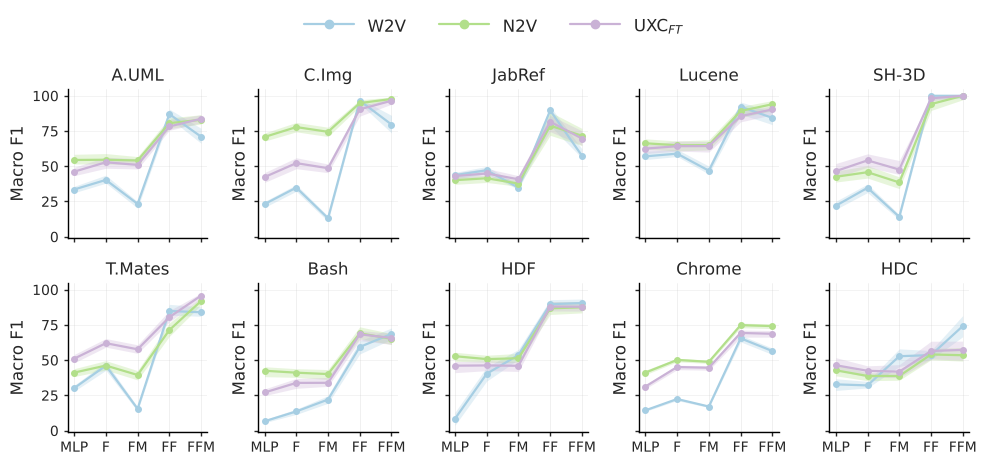

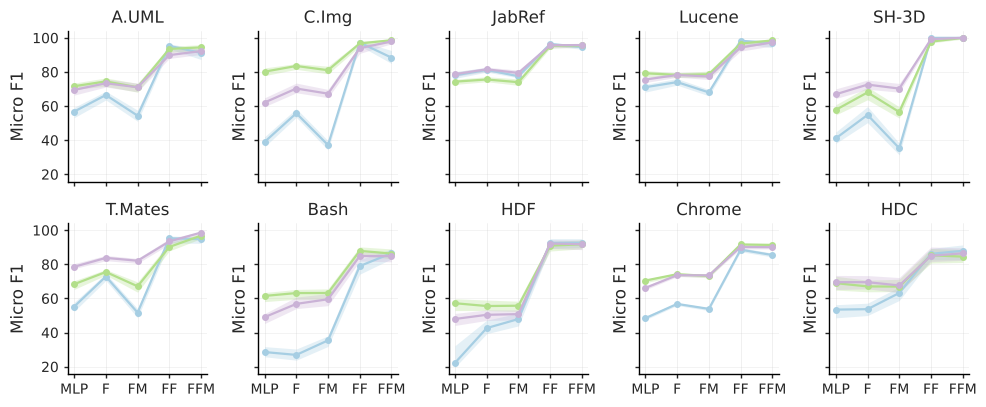

In [10]:
def lineplot_rq2(metric, save_path=None, size=(10, 4.2), nrows=2, ncols=5, legends=True, band_alpha=0.3):
    fig, axes = plt.subplots(nrows, ncols, figsize=size, sharey=True, sharex=True, squeeze=False)
    axes = axes.flatten()
    for ax, raw in zip(axes, SYSTEMS_RAW):
        for rep in RQ2_REPS:
            meds, q1, q3 = [], [], []
            for cfg in RQ2_CONFIGS:
                v = rq2_slice(rep, cfg).query("system == @raw")[metric].to_numpy()
                meds.append(np.median(v)); q1.append(np.percentile(v, 25)); q3.append(np.percentile(v, 75))
            ax.plot(RQ2_CONFIGS, meds, marker="o", markersize=4, linewidth=1.6, color=REP_COLOR[rep], label=REP_PLOT[rep], zorder=3)
            ax.fill_between(RQ2_CONFIGS, q1, q3, color=REP_COLOR[rep], alpha=band_alpha, linewidth=0, zorder=1)
        ax.set_title(SYS_RENAME.get(raw, raw)); ax.set_ylabel(METRIC_NAME[metric].replace("-", " "))
        ax.tick_params(axis="both", labelsize=10); ax.grid(axis="y", linewidth=0.4, alpha=0.4)
    for ax in axes[len(SYSTEMS_RAW):]:
        ax.set_visible(False)
    if legends:
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=len(l), fontsize=12, frameon=False,
                   handlelength=3, handleheight=1.5, markerscale=1.5, columnspacing=2.0)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
    plt.show()

lineplot_rq2("f1_macro", fig_path("RQ2_lineplot_f1_macro.pdf"))
lineplot_rq2("f1_micro", fig_path("RQ2_lineplot_f1_micro.pdf"), legends=False)

### Directory-hierarchy baseline (all 100 splits)
The package holds the per-split comparison of the existing directory rule with **UniXcoder-FT** FM and FFM predictions. Lost / gained = correct FM predictions lost and incorrect FM predictions corrected on the baseline-error subset (repeated file-split events, not unique files).
Repair is undefined where the baseline makes no error.

In [11]:
dsum = PKG.csv(f"{AUDIT_DIR}/directory_summary.csv")
dsum["system"] = dsum["system"].replace(SYS_RENAME)
d100 = dsum[dsum.splits == 100]
fm, ffm = (d100[d100.config == c].set_index("system").reindex(DATASET_ORDER) for c in ("FM", "FFM"))
dirtab = pd.DataFrame({
    "baseline_acc": ffm.baseline_accuracy_median, "baseline_errors_median": ffm.baseline_errors_median,
    "FM_acc": fm.model_accuracy_median, "FFM_acc": ffm.model_accuracy_median,
    "FM_minus_baseline": fm.model_accuracy_median - fm.baseline_accuracy_median, "FFM_minus_baseline": ffm.model_accuracy_median - ffm.baseline_accuracy_median,
    "FM_damage_pct": fm.damage_pct_median, "FFM_damage_pct": ffm.damage_pct_median,
    "FM_repair_pct": fm.repair_pct_median, "FFM_repair_pct": ffm.repair_pct_median,
    "lost_FM_to_FFM": ffm.lost_fm_to_ffm, "gained_FM_to_FFM": ffm.gained_fm_to_ffm})
display(dirtab.round(1))
save_stats(dirtab.reset_index().rename(columns={"index": "system"}), "directory_baseline_100splits.csv")

def tex_directory():
    f = lambda x, nd=1: "--" if pd.isna(x) else f"{x:.{nd}f}"
    L = [r"\begin{table*}[t]", r"\centering", r"\small",
         r"\caption{Directory hierarchy baseline versus FM and FFM with \ft{} features over 100 splits. Accuracy, repair and damage are medians over splits (\%); repair is undefined (--) when the baseline makes no error. "
         r"Lost/gained are correct FM predictions lost and incorrect FM predictions corrected by FFM among the baseline's errors, summed over splits (repeated file-split events, not unique files).\label{tab:directory_baseline}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\begin{tabular}{lrrrrrrrrr}", r"\toprule",
         r"& & \multicolumn{2}{c}{Accuracy} & \multicolumn{2}{c}{Repaired} & \multicolumn{2}{c}{Damaged} & \multicolumn{2}{c}{FM$\to$FFM} \\",
         r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}\cmidrule(lr){9-10}",
         r"System & Baseline & FM & FFM & FM & FFM & FM & FFM & Lost & Gained \\", r"\midrule"]
    for s, r in dirtab.iterrows():
        L.append(f"{s} & {f(r.baseline_acc)} & {f(r.FM_acc)} & {f(r.FFM_acc)} & {f(r.FM_repair_pct)} & {f(r.FFM_repair_pct)} & "
                 f"{f(r.FM_damage_pct)} & {f(r.FFM_damage_pct)} & {int(r.lost_FM_to_FFM)} & {int(r.gained_FM_to_FFM)} \\\\")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""])

write_table(tex_directory(), "directory_baseline.tex")

,baseline_acc,baseline_errors_median,FM_acc,FFM_acc,FM_minus_baseline,FFM_minus_baseline,FM_damage_pct,FFM_damage_pct,FM_repair_pct,FFM_repair_pct,lost_FM_to_FFM,gained_FM_to_FFM
system,,,,,,,,,,,,
A.UML,98.5,11.0,71.0,92.2,-27.4,-6.2,28.0,6.5,9.1,21.7,39,217
C.Img,100.0,0.0,67.3,97.9,-32.7,-2.1,32.7,2.1,NaN,NaN,0,0
JabRef,97.2,27.0,79.4,95.8,-17.8,-1.4,19.7,2.6,45.3,26.3,544,63
Lucene,91.5,85.5,77.4,97.3,-14.1,5.8,20.2,1.4,52.9,86.9,13,2551
SH-3D,100.0,0.0,70.3,100.0,-29.7,0.0,29.7,0.0,NaN,NaN,0,0
T.Mates,100.0,0.0,82.1,98.6,-17.9,-1.4,17.8,1.3,100.0,100.0,18,61
Bash,91.8,21.0,59.5,84.8,-32.3,-7.0,36.8,9.2,24.6,26.1,208,171
HDF,93.4,8.0,50.8,91.8,-42.6,-1.6,47.3,5.2,27.3,50.0,67,254
Chrome,96.8,574.0,73.5,90.0,-23.3,-6.8,24.5,7.6,19.8,20.0,4011,3525


saved results/unified200/stats/directory_baseline_100splits.csv  (10 rows)
updated first table of generated/directory_baseline.tex


In [12]:
# Numbers for the RQ2 text
fold = rq2_stats[rq2_stats.contrast.isin(["FF-F", "FFM-FM"])]
print(f"Folder steps: {len(fold)} comparisons, Holm-significant {int(fold.significant.sum())}, significant and large {int((fold.significant & (fold.cliffs_band == 'L')).sum())}, "
      f"fewest positive paired runs {int(fold.positive_splits.min())}/100")
display(rq2_summary[rq2_summary.contrast.isin(["FF-F", "FFM-FM"])].groupby(["contrast", "metric"]).median_system_difference.agg(["min", "max"]).round(2))
print(f"Directory baseline: accuracy {dirtab.baseline_acc.min():.0f}-{dirtab.baseline_acc.max():.0f}%; FM damage {dirtab.FM_damage_pct.min():.0f}-{dirtab.FM_damage_pct.max():.0f}%; "
      f"FM minus baseline {dirtab.FM_minus_baseline.min():.1f} to {dirtab.FM_minus_baseline.max():.1f} points; FFM damage at most {dirtab.FFM_damage_pct.max():.1f}%; "
      f"FFM minus baseline {dirtab.FFM_minus_baseline.min():.1f} to {dirtab.FFM_minus_baseline.max():.1f} points")
print("FFM above baseline:", dirtab.index[dirtab.FFM_minus_baseline > 0.005].tolist(), "| equal:", dirtab.index[dirtab.FFM_minus_baseline.abs() <= 0.005].tolist())
print("FFM repairs more than FM:", dirtab.index[dirtab.FFM_repair_pct > dirtab.FM_repair_pct].tolist(), "| fewer:", dirtab.index[dirtab.FFM_repair_pct < dirtab.FM_repair_pct].tolist())

Folder steps: 120 comparisons, Holm-significant 120, significant and large 120, fewest positive paired runs 96/100


min    max
contrast metric                
FF-F     f1_macro  25.57  44.41
         f1_micro  16.52  32.12
FFM-FM   f1_macro  28.94  42.98
         f1_micro  20.57  39.91

Directory baseline: accuracy 89-100%; FM damage 18-47%; FM minus baseline -42.6 to -14.1 points; FFM damage at most 9.2%; FFM minus baseline -7.0 to 5.8 points
FFM above baseline: ['Lucene'] | equal: ['SH-3D']
FFM repairs more than FM: ['A.UML', 'Lucene', 'Bash', 'HDF', 'Chrome'] | fewer: ['JabRef', 'HDC']


---
## 6. RQ3: neighbor information, predictor and edge direction
Conditions: `off`, `directed` (original dependency direction), `undirected` (bidirectional). Effects are paired within-split changes; a system's effect is the median over its 100 splits, a table cell the median over the ten systems.
For the neighbor-MLP, off is `[x, 0]` and on is `[x, mean(incoming neighbors)]`; GAT has no self-loops. One Holm family per vector, predictor, contrast and metric (ten systems).
This is not the difference of two medians; the two conventions can differ in sign, so never mix them.

In [13]:
MODEL_TEX = {"HGT": "HGT", "GAT": "GAT", "NeighborMLP": r"\mlp{}"}
MODEL_PLOT = {"HGT": "HGT", "GAT": "GAT", "NeighborMLP": r"$\mathcal{N}_\mathrm{MLP}$"}
CONTRASTS = [("directed", "off"), ("undirected", "off"), ("undirected", "directed")]
CONTRAST_TEX = {"directed-off": "dir.$-$off", "undirected-off": "undir.$-$off", "undirected-directed": "undir.$-$dir."}

rows = []
for rep in REPS:
    for model in MODELS:
        r = rq3[(rq3.representation == rep) & (rq3.model == model)]
        for a, b in CONTRASTS:
            rows += paired_compare(r[r.condition == a], r[r.condition == b], "RQ3", f"{rep}/{model}/{a}-{b}",
                                   contrast=f"{a}-{b}", representation=rep, model=model)
rq3_stats = finish_stats(rows)
check_against_package(rq3_stats, "RQ3")
save_stats(rq3_stats, "rq3_paired_statistics.csv")
rq3_summary = summarize(rq3_stats, ["scope", "representation", "model", "contrast", "metric"])

rows = []
for rep in REPS:
    for cond in ["off", "directed", "undirected"]:
        r = rq3[(rq3.representation == rep) & (rq3.condition == cond)]
        for a, b in [("GAT", "HGT"), ("NeighborMLP", "HGT"), ("GAT", "NeighborMLP")]:
            rows += paired_compare(r[r.model == a], r[r.model == b], "encoders", f"{rep}/{cond}/{a}-{b}",
                                   contrast=f"{a}-{b}", representation=rep, condition=cond)
enc_stats = finish_stats(rows)
check_against_package(enc_stats, "encoders")
save_stats(enc_stats, "rq3_predictor_paired_statistics.csv")
enc_summary = summarize(enc_stats, ["scope", "representation", "condition", "contrast", "metric"])

def summ_row(rep, model, contrast, metric):
    r = rq3_summary[(rq3_summary.representation == rep) & (rq3_summary.model == model) & (rq3_summary.contrast == contrast) & (rq3_summary.metric == metric)]
    assert len(r) == 1
    return r.iloc[0]

def tex_rq3_reps():
    L = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Change in F1 when neighbor information is switched on, by input vector and graph condition. Each cell gives the median over ten systems of the paired within-split change in F1 points, "
         r"followed in parentheses by the number of systems with a positive median change and the numbers of significant positive and negative changes (paired Wilcoxon, Holm). "
         r"Dir.: dependencies in their original direction; undir.: bidirectional; off: no neighbor information. Shading marks the median change: blue for gains, purple for losses, and darker for larger changes.\label{tab:rq3_reps}}",
         "", r"\begin{adjustbox}{max width=\textwidth}", r"\renewcommand{\arraystretch}{1.1}", r"\begin{tabular}{llrrrrrrrr}", r"\toprule",
         r"& & \multicolumn{2}{c}{N2V} & \multicolumn{2}{c}{W2V} & \multicolumn{2}{c}{\zs{}} & \multicolumn{2}{c}{\ft{}} \\",
         r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}\cmidrule(lr){9-10}",
         r"Model & Contrast & Macro F1 & Micro F1 & Macro F1 & Micro F1 & Macro F1 & Micro F1 & Macro F1 & Micro F1 \\", r"\midrule"]
    for mi, model in enumerate(MODELS):
        for ci, (a, b) in enumerate(CONTRASTS):
            c = []
            for rep in REPS:
                for metric in METRICS:
                    r = summ_row(rep, model, f"{a}-{b}", metric); x = r.median_system_paired_delta
                    c.append(shaded(x, f"{tex_signed(x)} ({r.paired_positive_systems}; {r.significant_positive}/{r.significant_negative})"))
            first = rf"\multirow{{3}}{{*}}{{{MODEL_TEX[model]}}}" if ci == 0 else ""
            L.append(f"{first} & {CONTRAST_TEX[f'{a}-{b}']} & " + " & ".join(c) + r" \\")
        if mi < len(MODELS) - 1:
            L.append(r"\addlinespace[3pt]")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""])

def tex_per_system_n2v():
    cols = [(m, c, metric) for m in MODELS for c in ("directed-off", "undirected-off") for metric in METRICS]
    L = [r"\begin{table*}[t]", r"\centering\small",
         r"\caption{Per-system change in macro-/micro-F1 (F1 points) when neighbor information is switched on, N2V, ten systems. Each value is the median paired change over 100 splits. "
         r"Blue: significant increase; pink: significant decrease (paired Wilcoxon, Holm across systems). Dir.: original direction; undir.: bidirectional.\label{tab:rq3_systems}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\begin{tabular}{l" + "r" * 12 + "}", r"\toprule",
         "& " + " & ".join(rf"\multicolumn{{4}}{{c}}{{{MODEL_TEX[m]}}}" for m in MODELS) + r" \\",
         r"\cmidrule(lr){2-5}\cmidrule(lr){6-9}\cmidrule(lr){10-13}",
         "& " + " & ".join(r"\multicolumn{2}{c}{" + t + "}" for _ in MODELS for t in ("Dir.", "Undir.")) + r" \\",
         r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}\cmidrule(lr){8-9}\cmidrule(lr){10-11}\cmidrule(lr){12-13}",
         "System & " + " & ".join("Macro & Micro" for _ in range(6)) + r" \\", r"\midrule"]
    tabs = {(m, c, metric): rq3_stats[(rq3_stats.representation == "N2V") & (rq3_stats.model == m) & (rq3_stats.contrast == c) & (rq3_stats.metric == metric)]
            .set_index("system").reindex(DATASET_ORDER) for m, c, metric in cols}
    for s in DATASET_ORDER:
        row = []
        for key in cols:
            r = tabs[key].loc[s]; t = tex_signed(r.median_paired_delta, 2)
            if r.significant:
                t = rf"\best{{{t}}}" if r.median_paired_delta > 0 else rf"\nb{{{t}}}"
            row.append(t)
        L.append(s + " & " + " & ".join(row) + r" \\")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""])

write_table(tex_rq3_reps(), "rq3_systems_body.tex")
write_table(tex_per_system_n2v(), "rq3_n2v.tex")
display(rq3_summary[rq3_summary.metric == "f1_macro"].pivot_table(index=["model", "contrast"], columns="representation",
                                                                  values="median_system_paired_delta")[REPS].round(2))

OK: RQ3 statistics (720 tests) reproduce paired_statistics.csv
saved results/unified200/stats/rq3_paired_statistics.csv  (720 rows)


OK: encoders statistics (720 tests) reproduce paired_statistics.csv
saved results/unified200/stats/rq3_predictor_paired_statistics.csv  (720 rows)


updated first table of generated/rq3_systems_body.tex
updated first table of generated/rq3_n2v.tex


representation                    N2V   W2V  UXC_ZS  UXC_FT
model       contrast                                       
GAT         directed-off        -2.84  1.46    3.79    0.67
            undirected-directed  3.81  1.92    3.33    2.98
            undirected-off       1.42  5.56    8.17    3.77
HGT         directed-off        -0.64  0.23    1.64    0.72
            undirected-directed  0.34  0.72   -0.03    0.57
            undirected-off       0.49  2.94    1.79    0.91
NeighborMLP directed-off        -0.65  3.41    4.81    2.85
            undirected-directed  1.62  1.33    3.54    3.11
            undirected-off       1.19  5.08    7.71    5.77

### Figure `rq3_n2v.pdf`: change in macro-F1 when neighbors are switched on (on minus off), N2V vectors
One panel per predictor; square = median paired change of a system over its 100 splits; filled = Holm-significant, hollow = not significant.
Same layout, colors (blue / red) and marker scheme as the previous figure; the two series are now directed and undirected neighbors instead of the two training schedules.

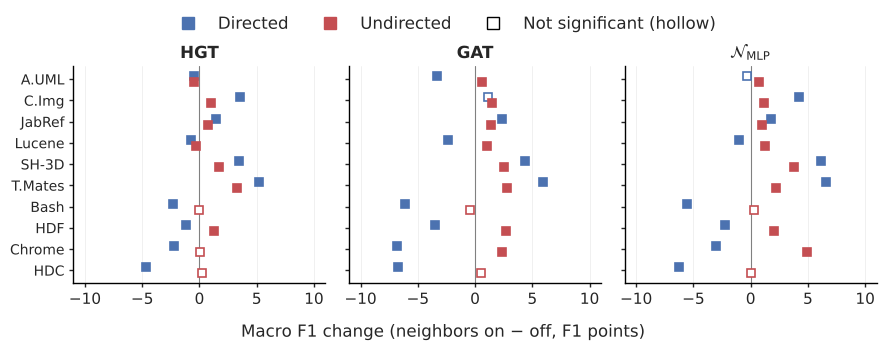

In [14]:
from matplotlib.lines import Line2D
SERIES_COLOR = {"directed-off": "#4c72b0", "undirected-off": "#c44e52"}     # the two colors of the previous figure
SERIES_LABEL = {"directed-off": "Directed", "undirected-off": "Undirected"}

def fig_onoff(rep="N2V", metric="f1_macro", name="rq3_n2v.pdf"):
    d = rq3_stats[(rq3_stats.representation == rep) & (rq3_stats.metric == metric)]
    fig, axes = plt.subplots(1, len(MODELS), figsize=(9, 3.3), sharey=True, sharex=True)
    y0 = np.arange(len(DATASET_ORDER))
    for ax, model in zip(axes, MODELS):
        for j, c in enumerate(SERIES_COLOR):
            g = d[(d.model == model) & (d.contrast == c)].set_index("system").reindex(DATASET_ORDER)
            y = y0 + (j - 0.5) * 0.28
            for yi, (_, r) in zip(y, g.iterrows()):
                ax.plot(r.median_paired_delta, yi, "s", color=SERIES_COLOR[c], mfc=SERIES_COLOR[c] if r.significant else "white", mew=1.2, ms=5.5, zorder=3)
        ax.axvline(0, color="grey", lw=0.8)
        ax.set_title(MODEL_PLOT[model], fontweight="bold", fontsize=12)
        ax.tick_params(axis="y", labelsize=10)
    axes[0].set_yticks(y0, DATASET_ORDER); axes[0].invert_yaxis()
    lim = int(np.ceil(np.nanmax(np.abs(d["median_paired_delta"].values)))) + 1
    ticks = np.arange(-(lim // 5) * 5, (lim // 5) * 5 + 1, 5)
    axes[0].set_xticks(ticks); axes[0].set_xlim(-lim, lim)
    fig.supxlabel(f"{METRIC_NAME[metric].replace('-F1', ' F1')} change (neighbors on $-$ off, F1 points)", fontsize=12, y=0.05)
    h = [Line2D([], [], marker="s", color=SERIES_COLOR[c], ls="", mfc=SERIES_COLOR[c], label=SERIES_LABEL[c]) for c in SERIES_COLOR]
    h.append(Line2D([], [], marker="s", color="black", ls="", mfc="white", label="Not significant (hollow)"))
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=len(h), fontsize=12, frameon=False, markerscale=1.5, columnspacing=1.5)
    fig.tight_layout()
    fig.savefig(fig_path(name), bbox_inches="tight")
    plt.show()

fig_onoff("N2V", "f1_macro", "rq3_n2v.pdf")

### Which predictor is best on each graph? (`rq3_encoders.tex`)
Median over systems of the per-system median score; in parentheses the number of systems on which the predictor is best. The systems are shared, so wins are descriptive, not significance claims
(paired GAT-HGT / MLP-HGT / GAT-MLP tests: `stats/rq3_predictor_paired_statistics.csv`). Exact ties go to the first model alphabetically, as in the package.

In [15]:
med = rq3.groupby(["system", "representation", "model", "condition"])[METRICS].median().reset_index()
med["system"] = med["system"].replace(SYS_RENAME)

def encoder_table(metric, cond):
    t = med[med.condition == cond].pivot(index=["system", "representation"], columns="model", values=metric)[MODELS]
    wins = (t[sorted(MODELS)].idxmax(axis=1).groupby(level="representation").value_counts().unstack(fill_value=0).reindex(columns=MODELS, fill_value=0))
    return t.groupby(level="representation").median()[MODELS].reindex(REPS), wins.reindex(REPS)

enc = {(m, c): encoder_table(m, c) for m in METRICS for c in ["off", "directed", "undirected"]}
ref = PKG.csv(f"{AUDIT_DIR}/encoder_wins.csv")
for (metric, cond), (c, w) in enc.items():
    for rep in REPS:
        for model in MODELS:
            exp = ref[(ref.metric == metric) & (ref.condition == cond) & (ref.representation == rep) & (ref.model == model)].wins
            assert int(w.loc[rep, model]) == (int(exp.iloc[0]) if len(exp) else 0), (metric, cond, rep, model)
print("OK: win counts reproduce encoder_wins.csv")

def tex_encoders():
    L = [r"\begin{table*}[t]", r"\centering",
         r"\caption{Median F1 over ten systems for each predictor on the directed and the undirected file graph, by input vector. In parentheses: number of systems on which the predictor has the highest median score. "
         r"Highlighted: highest median in each row and graph condition. HGT, GAT and \mlp{} have different parameter counts.\label{tab:rq3_encoders}}",
         r"\begin{adjustbox}{max width=\textwidth}", r"\renewcommand{\arraystretch}{1.1}", r"\begin{tabular}{llrrrrrr}", r"\toprule",
         r"& & \multicolumn{3}{c}{Directed} & \multicolumn{3}{c}{Undirected} \\", r"\cmidrule(lr){3-5}\cmidrule(lr){6-8}",
         r"Metric & Vector & HGT & GAT & \mlp{} & HGT & GAT & \mlp{} \\", r"\midrule"]
    for mi, metric in enumerate(METRICS):
        for ri, rep in enumerate(REPS):
            c_ = []
            for cond in ("directed", "undirected"):
                c, w = enc[(metric, cond)]; best = c.loc[rep].idxmax()
                for model in MODELS:
                    t = f"{c.loc[rep, model]:.1f} ({int(w.loc[rep, model])})"
                    c_.append(rf"\best{{{t}}}" if model == best else t)
            first = rf"\multirow{{4}}{{*}}{{{METRIC_NAME[metric].replace('-F1', ' F1')}}}" if ri == 0 else ""
            L.append(f"{first} & {REP_LABEL[rep]} & " + " & ".join(c_) + r" \\")
        if mi == 0:
            L.append(r"\midrule")
    return "\n".join(L + [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}", ""])

write_table(tex_encoders(), "rq3_encoders.tex")

OK: win counts reproduce encoder_wins.csv
updated first table of generated/rq3_encoders.tex


In [16]:
# Numbers for the RQ3 text
print("N2V, macro-F1: median system paired change (positive systems; sig+/sig-)")
for model in MODELS:
    for a, b in CONTRASTS:
        r = summ_row("N2V", model, f"{a}-{b}", "f1_macro")
        print(f"  {model:<12} {a}-{b:<11} {r.median_system_paired_delta:+.2f}  ({r.paired_positive_systems}; {r.significant_positive}/{r.significant_negative})")
neg = rq3_stats[(rq3_stats.contrast == "undirected-directed") & (rq3_stats.metric == "f1_macro") & (rq3_stats.median_paired_delta < 0)]
print("\nSystems where undirected is worse than directed (macro-F1, negative paired median):")
display(neg.groupby(["representation", "model"]).system.apply(lambda s: ", ".join(s)).unstack())
loss = rq3_stats[(rq3_stats.representation == "N2V") & (rq3_stats.metric == "f1_macro") & rq3_stats.significant & (rq3_stats.median_paired_delta < 0)
                 & rq3_stats.contrast.isin(["directed-off", "undirected-off"])]
print("Holm-significant losses from neighbors, N2V macro-F1:")
display(loss.groupby(["model", "contrast"]).system.apply(lambda s: ", ".join(s)))
for metric in METRICS:
    per = {rep: int(enc[(metric, "undirected")][1].loc[rep, "GAT"]) for rep in REPS}
    print(f"GAT wins on the undirected graph, {METRIC_NAME[metric]}: {sum(per.values())}/40 {per}")
print("Directed graph, N2V wins:", {m: dict(enc[(m, 'directed')][1].loc['N2V']) for m in METRICS})
print("\nNeighbors off, GAT minus neighbor-MLP (median system difference):")
display(enc_summary[(enc_summary.condition == "off") & (enc_summary.contrast == "GAT-NeighborMLP")]
        .pivot_table(index="representation", columns="metric", values="median_system_difference").round(2))

N2V, macro-F1: median system paired change (positive systems; sig+/sig-)
  HGT          directed-off         -0.64  (4; 4/6)
  HGT          undirected-off         +0.49  (8; 5/2)
  HGT          undirected-directed    +0.34  (6; 5/4)
  GAT          directed-off         -2.84  (4; 3/6)
  GAT          undirected-off         +1.42  (9; 8/0)
  GAT          undirected-directed    +3.81  (7; 6/2)
  NeighborMLP  directed-off         -0.65  (4; 4/5)
  NeighborMLP  undirected-off         +1.19  (10; 8/0)
  NeighborMLP  undirected-directed    +1.62  (6; 6/4)

Systems where undirected is worse than directed (macro-F1, negative paired median):


model,GAT,HGT,NeighborMLP
representation,,,
N2V,"JabRef, SH-3D, T.Mates","C.Img, JabRef, SH-3D, T.Mates","C.Img, JabRef, SH-3D, T.Mates"
UXC_FT,"C.Img, JabRef, SH-3D, T.Mates","C.Img, JabRef, SH-3D, T.Mates","C.Img, JabRef, SH-3D, T.Mates"
UXC_ZS,"C.Img, JabRef, SH-3D, T.Mates","A.UML, C.Img, JabRef, SH-3D, T.Mates","C.Img, JabRef, SH-3D, T.Mates"
W2V,"JabRef, SH-3D, T.Mates","JabRef, SH-3D, T.Mates","JabRef, SH-3D, T.Mates, HDF"


Holm-significant losses from neighbors, N2V macro-F1:


model        contrast      
GAT          directed-off      A.UML, Lucene, Bash, HDF, Chrome, HDC
HGT          directed-off      A.UML, Lucene, Bash, HDF, Chrome, HDC
             undirected-off                            A.UML, Lucene
NeighborMLP  directed-off             Lucene, Bash, HDF, Chrome, HDC
Name: system, dtype: str

GAT wins on the undirected graph, Macro-F1: 33/40 {'N2V': 6, 'W2V': 10, 'UXC_ZS': 10, 'UXC_FT': 7}
GAT wins on the undirected graph, Micro-F1: 33/40 {'N2V': 4, 'W2V': 9, 'UXC_ZS': 10, 'UXC_FT': 10}
Directed graph, N2V wins: {'f1_macro': {'HGT': np.int64(6), 'GAT': np.int64(0), 'NeighborMLP': np.int64(4)}, 'f1_micro': {'HGT': np.int64(9), 'GAT': np.int64(0), 'NeighborMLP': np.int64(1)}}

Neighbors off, GAT minus neighbor-MLP (median system difference):


metric,f1_macro,f1_micro
representation,,
N2V,0.21,-0.02
UXC_FT,5.20,2.69
UXC_ZS,3.91,1.88
W2V,6.58,5.07


---
## 7. Checks against the supervisor's report
The notebook stops if a recomputed number differs from `REPORT.md`.

In [17]:
def one(df, **q):
    for k, v in q.items():
        df = df[df[k] == v]
    assert len(df) == 1, q
    return df.iloc[0]

# RQ1
assert round(rq1_med["f1_macro"].loc["A.UML", "N2V"], 2) == 54.46 and round(rq1_med["f1_micro"].loc["T.Mates", "UXC_FT"], 2) == 78.56
sh = one(rq1_stats, contrast="UXC_FT-UXC_ZS", system="SH-3D", metric="f1_macro")
assert round(sh.median_paired_delta, 2) == -0.43 and round(sh.p_holm, 3) == 0.566 and not sh.significant
assert all(rq1_med[m].idxmax(axis=1).value_counts()["N2V"] == 6 for m in METRICS)
# RQ2
for c, rep, m, v, pos in [("F-MLP", "N2V", "f1_macro", 0.76, 6), ("F-MLP", "W2V", "f1_macro", 7.50, 9), ("FF-F", "W2V", "f1_macro", 44.41, 10),
                          ("FFM-FM", "UXC_FT", "f1_macro", 32.28, 10), ("FM-F", "W2V", "f1_macro", -12.24, 3), ("FFM-FF", "W2V", "f1_macro", -4.40, 3)]:
    r = one(rq2_summary, contrast=c, representation=rep, metric=m)
    assert round(r.median_system_difference, 2) == v and r.positive_systems == pos, (c, rep)
assert int(fold.significant.sum()) == 120 and (fold.cliffs_band == "L").all() and int(fold.positive_splits.min()) == 96
assert int(ffm.loc["JabRef", "lost_fm_to_ffm"]) == 544 and int(ffm.loc["Chrome", "lost_fm_to_ffm"]) == 4011 and int(ffm.loc["Lucene", "gained_fm_to_ffm"]) == 2551
# RQ3
for (rep, model, c), (v, pos, sp, sn) in {
    ("N2V", "GAT", "directed-off"): (-2.84, 4, 3, 6), ("N2V", "HGT", "directed-off"): (-0.64, 4, 4, 6), ("N2V", "NeighborMLP", "directed-off"): (-0.65, 4, 4, 5),
    ("UXC_ZS", "GAT", "directed-off"): (3.79, 10, 9, 0), ("W2V", "HGT", "directed-off"): (0.23, 5, 4, 5), ("N2V", "GAT", "undirected-off"): (1.42, 9, 8, 0),
    ("N2V", "HGT", "undirected-off"): (0.49, 8, 5, 2), ("N2V", "NeighborMLP", "undirected-off"): (1.19, 10, 8, 0), ("UXC_ZS", "GAT", "undirected-off"): (8.17, 10, 10, 0),
    ("W2V", "HGT", "undirected-off"): (2.94, 7, 7, 3), ("UXC_FT", "NeighborMLP", "undirected-off"): (5.77, 10, 10, 0)}.items():
    r = summ_row(rep, model, c, "f1_macro")
    assert (round(r.median_system_paired_delta, 2), r.paired_positive_systems, r.significant_positive, r.significant_negative) == (v, pos, sp, sn), (rep, model, c)
assert all(sum(int(enc[(m, "undirected")][1].loc[r, "GAT"]) for r in REPS) == 33 for m in METRICS)
g = enc_summary[(enc_summary.condition == "off") & (enc_summary.contrast == "GAT-NeighborMLP") & (enc_summary.metric == "f1_macro")].set_index("representation")
assert round(g.loc["W2V", "median_system_difference"], 2) == 6.58 and round(g.loc["UXC_FT", "median_system_difference"], 2) == 5.20
print("OK: all spot checks match REPORT.md\n")
print("Tables :", sorted(p.name for p in TEX_DIR.glob("*.tex")))
print("Figures:", ["RQ2_lineplot_f1_macro.pdf", "RQ2_lineplot_f1_micro.pdf", "rq3_n2v.pdf"])

OK: all spot checks match REPORT.md

Tables : ['confirmation_graphs.tex', 'directory_baseline.tex', 'embedding_controls.tex', 'full_controls.tex', 'gat_controls.tex', 'pilot_controls.tex', 'rq1_mlp_features.tex', 'rq1_stats.tex', 'rq2_stats.tex', 'rq3_encoders.tex', 'rq3_n2v.tex', 'rq3_systems_UXC_FT.tex', 'rq3_systems_UXC_ZS.tex', 'rq3_systems_W2V.tex', 'rq3_systems_body.tex']
Figures: ['RQ2_lineplot_f1_macro.pdf', 'RQ2_lineplot_f1_micro.pdf', 'rq3_n2v.pdf']
